# Kalman Filter Test

This notebook tests and tunes the Kalman Filter implementation.

In [1]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import sys
import tdmclient.notebook as tdm
import time
import polars as pl
from tqdm import tqdm

sys.path.append('../')

from src.filtering import ExtendedKalmanFilter

x,mean,var
i64,f64,f64
2,2.0,1.0
3,3.0,23.333333
1,1.333333,0.333333


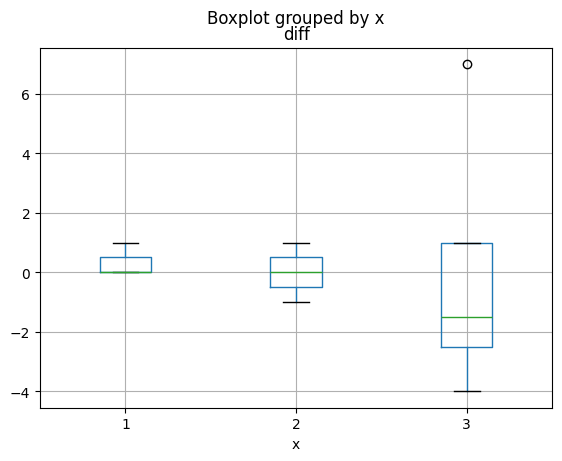

In [27]:
frame = pl.DataFrame({
    "x": [1, 1, 1, 2, 2, 2, 3, 3, 3, 3],
    "y": [1, 2, 1, 1, 2, 3, 1, -1, 2, 10]
}).with_columns(diff=pl.col("y") - pl.col("x"))

frame.to_pandas().boxplot(by="x", column="diff")
frame.group_by("x").agg(mean=pl.col("y").mean(), var=pl.col("y").var())

In [30]:
# connect to robot and declare functions

await tdm.start()
print("Connected to Thymio")

@tdm.sync_var
def robot_set_speed(right, left):
    global motor_right_target, motor_left_target
    motor_right_target = right
    motor_left_target = left

@tdm.sync_var
def robot_stop():
    global motor_right_target, motor_left_target
    motor_right_target = 0
    motor_left_target = 0

@tdm.sync_var
def robot_get_speed():
    global motor_right_speed, motor_left_speed
    return motor_right_speed, motor_left_speed

@tdm.sync_var
def robot_get_ground():
    global prox_ground_delta
    return prox_ground_delta

Connected to Thymio


In [3]:
%%run_python

# load empty python file to clear robot memory

## Sample data

At multiple speed levels:
1. Sample speed command vs. actual measured wheel speeds to quantify measurement noise
2. Sample speed command vs. measured pose to quantify nonlinear speed mapping from thymio space to mm/sec

In [ ]:
# function to drive robot and sample speeds

def sample_constant_speed(v_right, v_left, duration_sec, dt_sec, warmup_sec=1.0):

    # Let 1 sec to reach speed
    print("Warmup to stabilize speed...")
    robot_set_speed(v_right, v_left)
    time.sleep(warmup_sec)

    # Sample data
    start = time.time()
    last_meas = start

    samples = int(duration_sec / dt_sec)
    pbar = tqdm(total=samples, desc="Sampling", unit="samples")

    times = []
    cmd_r = []
    cmd_l = []
    meas_r = []
    meas_l = []

    while True:
        current_time = time.time()
        if current_time - last_meas > dt_sec:

            # take sample
            v_r, v_l = robot_get_speed()

            times.append(current_time - start)
            cmd_r.append(v_right)
            cmd_l.append(v_left)
            meas_r.append(v_r)
            meas_l.append(v_l)

            pbar.update()

            last_meas = current_time

        if current_time - start > duration_sec + dt_sec: # allow last sample
            robot_stop()
            break

    pbar.close()
            
    # Initialize data frame
    samples = pl.DataFrame({
        "time": times,
        "cmd_r": cmd_r,
        "cmd_l": cmd_l,
        "meas_r": meas_r,
        "meas_l": meas_l,
    })

    return samples
    

#### 1. Sample different speeds to measure command -> measurement noise

Get 100 samples each

In [ ]:
experiment = pl.DataFrame()

speeds = [50, 100, 250, 500]
samples_per_speed = 100
sample_period = 0.2 # sec
duration = samples_per_speed*sample_period # sec
warmup = 2.0 # sec

for speed in speeds:
    print(f"Sample at speed {speed}:")
    samples = sample_constant_speed(speed, speed, duration, sample_period, warmup)

    experiment = pl.concat((experiment, samples))

In [29]:
robot_stop()

In [ ]:
experiment.head()

time,cmd_r,cmd_l,meas_r,meas_l
f64,i64,i64,i64,i64
0.2,50,50,50,48
0.4,50,50,49,43
0.6,50,50,50,44
0.8,50,50,46,109
1.0,50,50,49,52


In [ ]:
# Boxplot of the results
experiment.to_pandas().boxplot(by="cmd_r", column="meas_r", title="Right Wheel speeds")

In [14]:
# disconnect the robot

await tdm.stop()
print("Disconnected from Thymio")

Disconnected from Thymio
